<a href="https://colab.research.google.com/github/mdsalim0786/AI-ML-Project/blob/main/Instructor_Effectiveness_Modeling_(EdTech_Context).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Stage 1 - Data Loading & Understanding**

Load Excel, inspect columns, shape and data types.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

print("Dataset loaded successfully!")

Saving instructor_effectiveness_dataset_2000_rows.xlsx to instructor_effectiveness_dataset_2000_rows.xlsx
Dataset loaded successfully!


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())

print("\nDataset Information:")
df.info()

Dataset Shape: (2000, 12)

First 5 Records:


,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710



Last 5 Records:


,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
1995,B_1131,I_047,C_17,0.589309,19.227979,46.242023,0.433437,0.848756,0.641781,0.261656,4.339478,0.643116
1996,B_1295,I_037,C_25,0.980000,36.737265,93.249093,0.103561,1.000000,0.688175,0.375195,4.912936,0.959988
1997,B_0861,I_033,C_06,0.531447,24.907878,83.990693,0.512266,0.918924,0.598276,0.271701,4.211113,0.773437
1998,B_1460,I_069,C_10,0.641025,22.395362,80.044231,0.317231,0.558183,0.575629,0.135500,4.182141,0.962627
1999,B_1127,I_045,C_22,0.300000,23.101794,86.891153,0.700000,0.563834,0.538691,0.210189,4.420309,0.545611



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


In [4]:
print("Total Columns:", len(df.columns))

for col in df.columns:
    print(col)

Total Columns: 12
batch_id
instructor_id
course_id
completion_rate
avg_score_improvement
avg_quiz_score
dropout_rate
avg_watch_time
assignment_submission_rate
forum_activity_rate
avg_feedback_score
feedback_response_rate


In [6]:
df.describe()

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


In [5]:
print("Total Batches:", df['batch_id'].nunique())

print("Total Instructors:", df['instructor_id'].nunique())

print("Total Courses:", df['course_id'].nunique())

Total Batches: 2000
Total Instructors: 120
Total Courses: 25


**Stage 2 - Data Cleaning & Exploratory Data Analysis (EDA)**
Objective: Understand data quality, distributions, relationships and anomalies.

In [9]:
missing = df.isnull().sum()

missing_df = pd.DataFrame({
    'Column': missing.index,
    'Missing Values': missing.values,
    'Missing Percentage': (
        missing.values / len(df) * 100
    )
})

display(missing_df)

,Column,Missing Values,Missing Percentage
0,batch_id,0,0.0
1,instructor_id,0,0.0
2,course_id,0,0.0
3,completion_rate,0,0.0
4,avg_score_improvement,0,0.0
5,avg_quiz_score,0,0.0
6,dropout_rate,0,0.0
7,avg_watch_time,0,0.0
8,assignment_submission_rate,0,0.0
9,forum_activity_rate,0,0.0


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Batch IDs:",
      df['batch_id'].duplicated().sum())

In [10]:
numeric_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_cols = df.select_dtypes(
    include=['object']
).columns

# Fill numerical missing values using median
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill categorical missing values
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [11]:
rate_columns = [
    'completion_rate',
    'dropout_rate',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'feedback_response_rate'
]

for col in rate_columns:
    print(
        col,
        "Invalid values:",
        (~df[col].between(0, 1)).sum()
    )

print(
    "Invalid feedback:",
    (~df['avg_feedback_score'].between(1, 5)).sum()
)

completion_rate Invalid values: 0
dropout_rate Invalid values: 0
avg_watch_time Invalid values: 0
assignment_submission_rate Invalid values: 0
forum_activity_rate Invalid values: 0
feedback_response_rate Invalid values: 0
Invalid feedback: 0


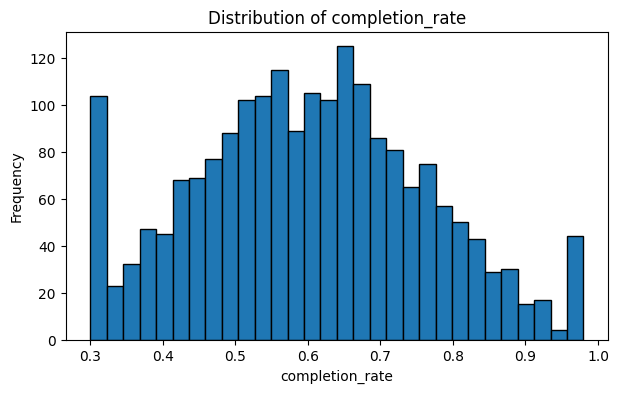

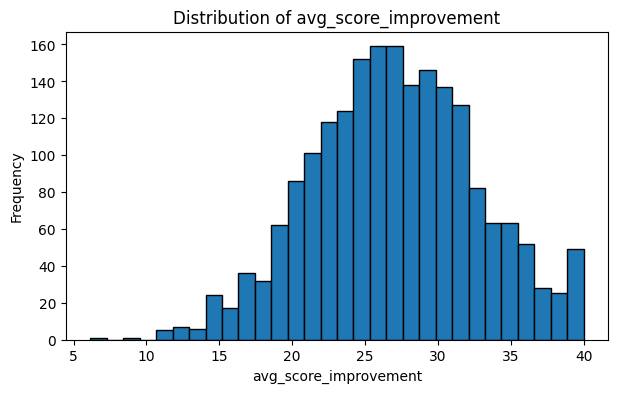

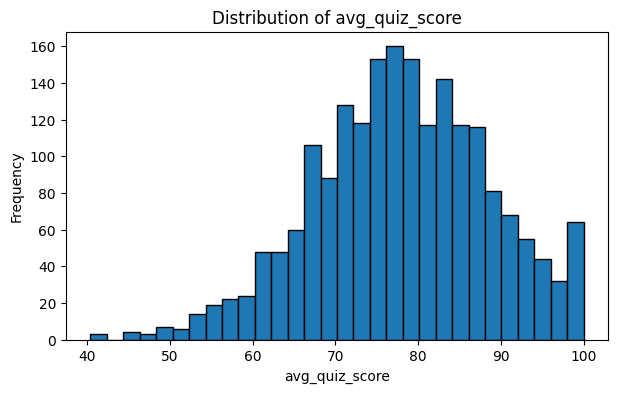

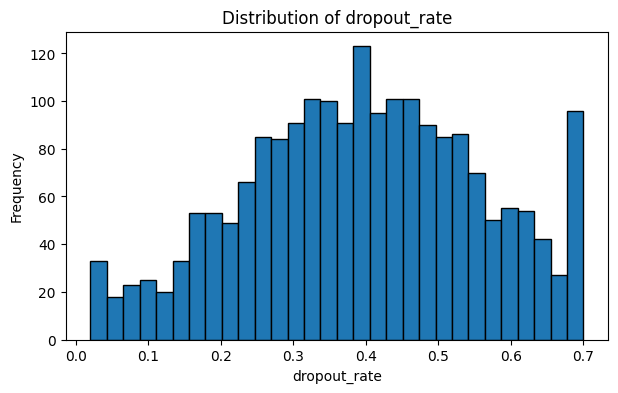

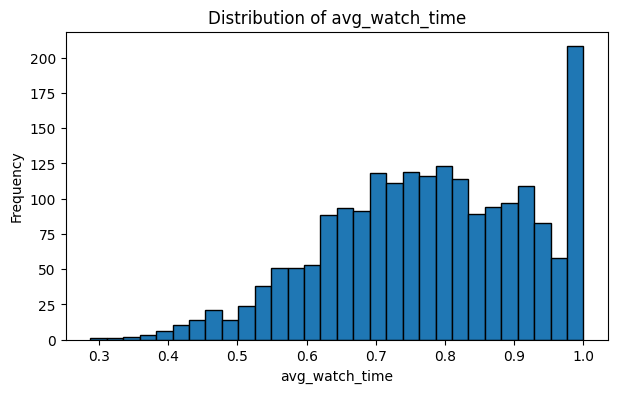

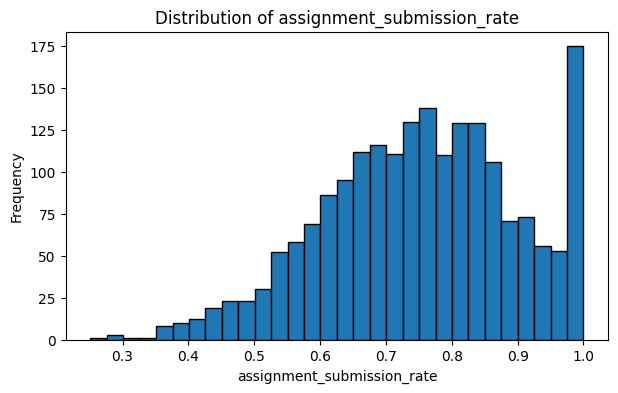

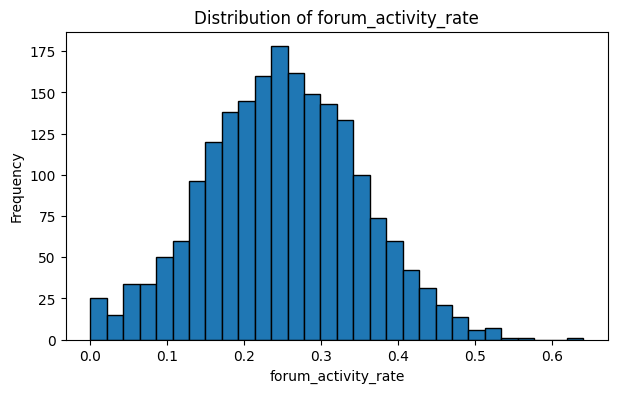

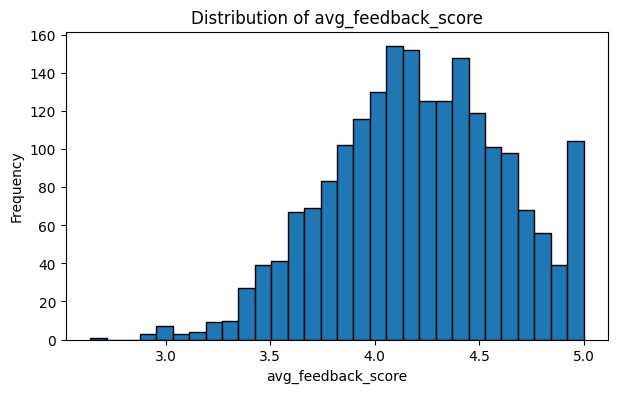

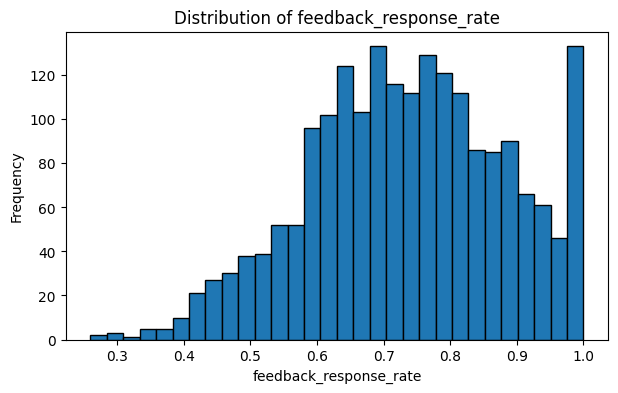

In [12]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:

    plt.figure(figsize=(7, 4))

    plt.hist(
        df[col],
        bins=30,
        edgecolor='black'
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.show()

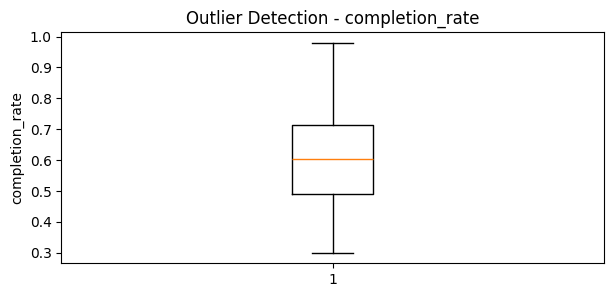

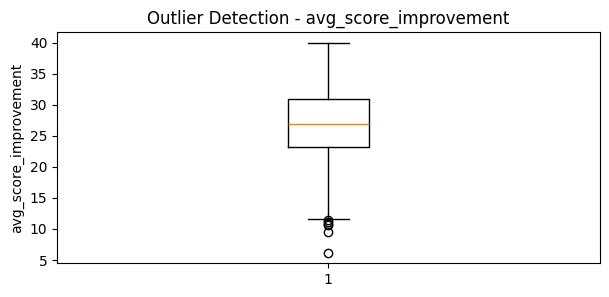

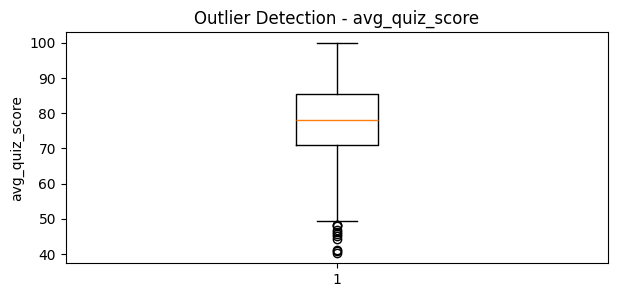

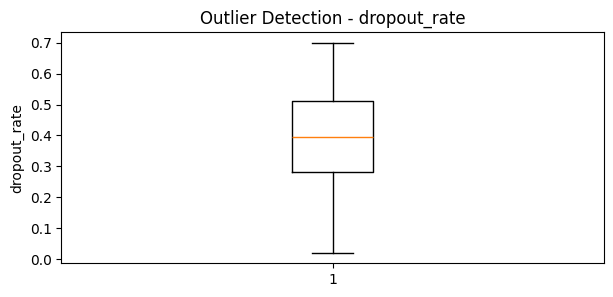

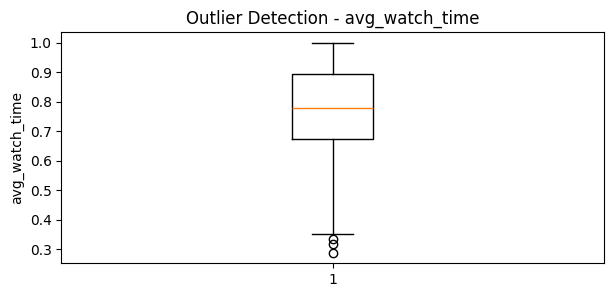

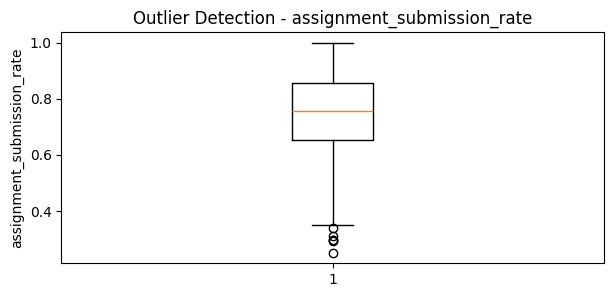

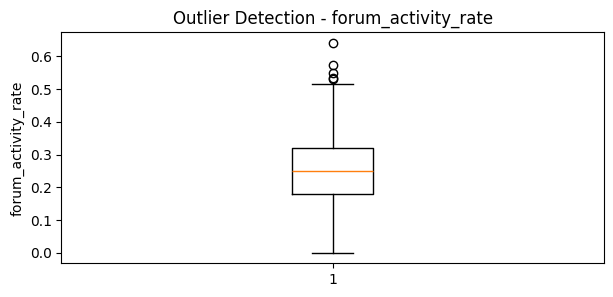

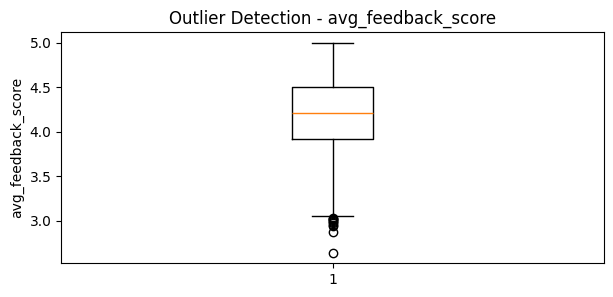

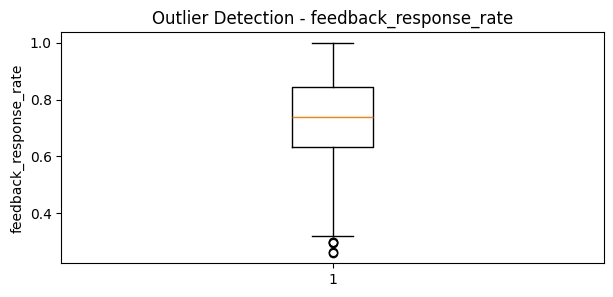

In [13]:
for col in numeric_cols:

    plt.figure(figsize=(7, 3))

    plt.boxplot(df[col])

    plt.title(f'Outlier Detection - {col}')
    plt.ylabel(col)

    plt.show()

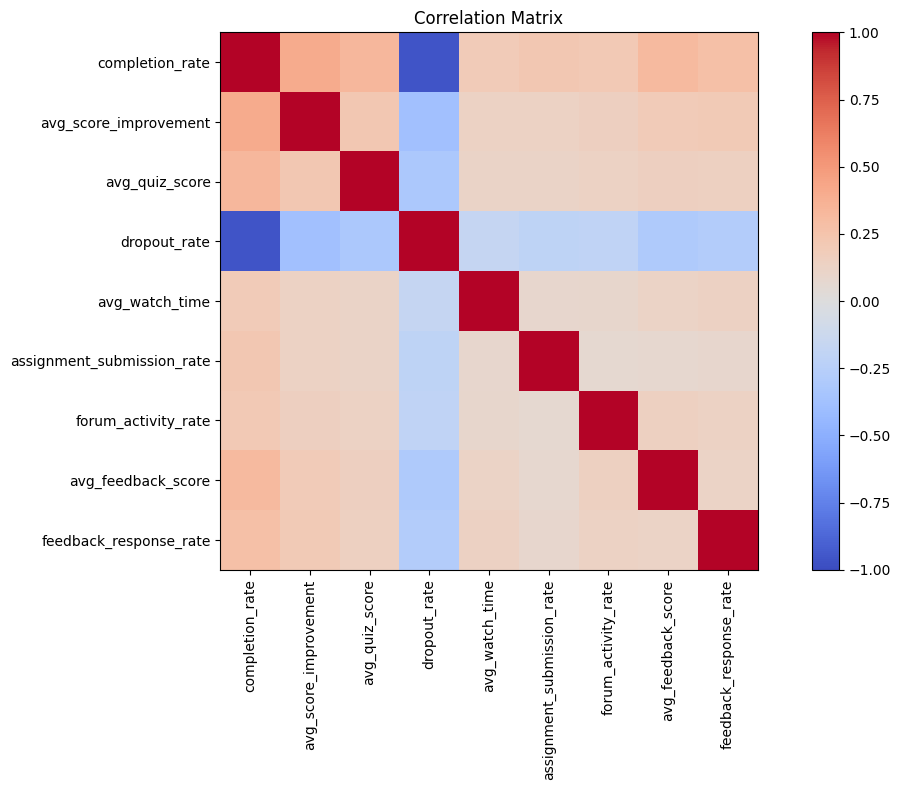

In [14]:
correlation = df[numeric_cols].corr()

plt.figure(figsize=(12, 8))

plt.imshow(
    correlation,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

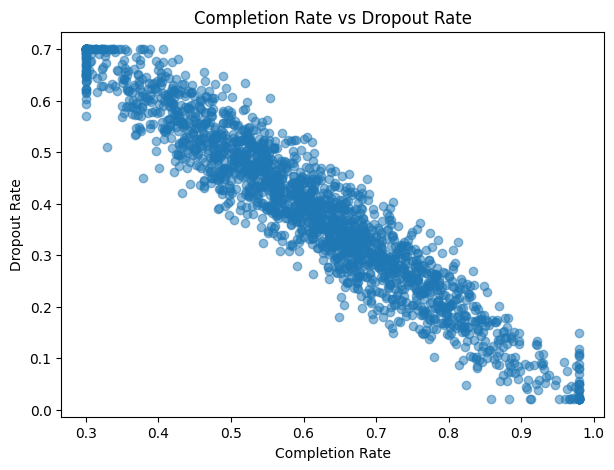

In [15]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df['completion_rate'],
    df['dropout_rate'],
    alpha=0.5
)

plt.xlabel('Completion Rate')
plt.ylabel('Dropout Rate')

plt.title('Completion Rate vs Dropout Rate')

plt.show()

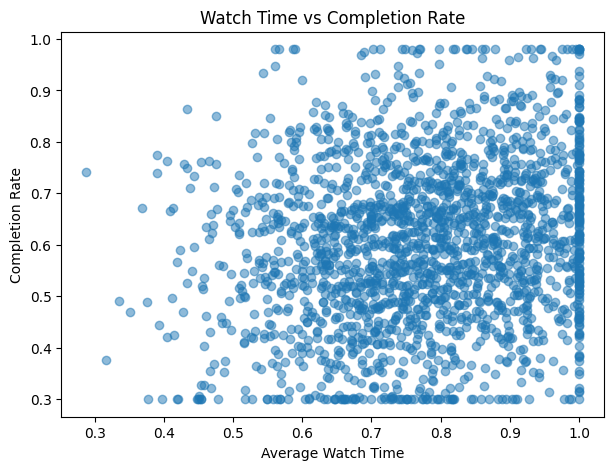

In [8]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df['avg_watch_time'],
    df['completion_rate'],
    alpha=0.5
)

plt.xlabel('Average Watch Time')
plt.ylabel('Completion Rate')

plt.title('Watch Time vs Completion Rate')

plt.show()

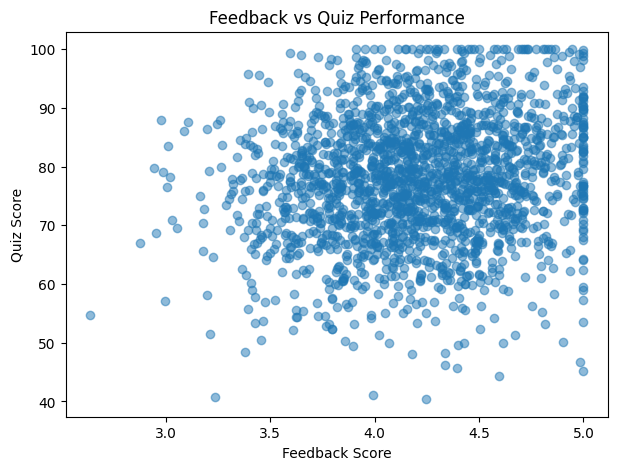

In [7]:
plt.figure(figsize=(7, 5))

plt.scatter(
    df['avg_feedback_score'],
    df['avg_quiz_score'],
    alpha=0.5
)

plt.xlabel('Feedback Score')
plt.ylabel('Quiz Score')

plt.title('Feedback vs Quiz Performance')

plt.show()

**Stage 3 - Create Instructor Effectiveness Score**
Objective: Create a score between 0 and 100 based on three dimensions.

In [16]:
df['completion_norm'] = df['completion_rate'].clip(0, 1)

df['dropout_inverse'] = (
    1 - df['dropout_rate'].clip(0, 1)
)

# Assumption: score improvement is normalized to 0–40
df['improvement_norm'] = (
    df['avg_score_improvement'].clip(0, 40) / 40
)

# Quiz score normalized to 0–100
df['quiz_norm'] = (
    df['avg_quiz_score'].clip(0, 100) / 100
)

df['outcome_score'] = 100 * (
    0.40 * df['completion_norm'] +
    0.20 * df['dropout_inverse'] +
    0.20 * df['improvement_norm'] +
    0.20 * df['quiz_norm']
)

display(df[['instructor_id', 'outcome_score']].head())

,instructor_id,outcome_score
0,I_044,40.873817
1,I_119,64.684878
2,I_050,41.956496
3,I_024,70.876528
4,I_001,66.089554


In [17]:
df['engagement_score'] = 100 * (

    0.40 * df['avg_watch_time'] +

    0.35 * df['assignment_submission_rate'] +

    0.25 * df['forum_activity_rate']

)

display(df[['instructor_id', 'engagement_score']].head())

,instructor_id,engagement_score
0,I_044,61.375377
1,I_119,61.760993
2,I_050,72.546812
3,I_024,60.579909
4,I_001,73.311232


In [18]:
feedback = df['avg_feedback_score'].clip(1, 5)

df['feedback_score'] = 100 * (

    0.70 * ((feedback - 1) / 4) +

    0.30 * df['feedback_response_rate']

)

display(df[['instructor_id', 'feedback_score']].head())

,instructor_id,feedback_score
0,I_044,64.404492
1,I_119,92.022623
2,I_050,64.497257
3,I_024,86.132616
4,I_001,80.860322


In [19]:
df['effectiveness_score'] = (

    0.45 * df['outcome_score'] +

    0.30 * df['engagement_score'] +

    0.25 * df['feedback_score']

)

display(
    df[
        ['batch_id',
         'instructor_id',
         'outcome_score',
         'engagement_score',
         'feedback_score',
         'effectiveness_score']
    ].head(10)
)

,batch_id,instructor_id,outcome_score,engagement_score,feedback_score,effectiveness_score
0,B_1861,I_044,40.873817,61.375377,64.404492,52.906954
1,B_0354,I_119,64.684878,61.760993,92.022623,70.642149
2,B_1334,I_050,41.956496,72.546812,64.497257,56.768781
3,B_0906,I_024,70.876528,60.579909,86.132616,71.601564
4,B_1290,I_001,66.089554,73.311232,80.860322,71.948750
5,B_1274,I_026,62.946406,60.891922,67.246849,63.405171
6,B_0939,I_082,68.126001,62.706412,87.448574,71.330768
7,B_1732,I_009,64.009593,68.559082,75.586683,68.268712
8,B_0066,I_114,80.254401,59.646296,73.317041,72.337629
9,B_1324,I_038,41.698672,47.012340,52.317017,45.947359


**Stage 4 - Aggregate Batch Data to Instructor Level**
Objective: Convert 2,000 batch records into 120 instructor-level records.

In [20]:
instructor_df = df.groupby('instructor_id').agg({

    'completion_rate': 'mean',

    'dropout_rate': 'mean',

    'avg_score_improvement': 'mean',

    'avg_quiz_score': 'mean',

    'avg_watch_time': 'mean',

    'assignment_submission_rate': 'mean',

    'forum_activity_rate': 'mean',

    'avg_feedback_score': 'mean',

    'feedback_response_rate': 'mean',

    'outcome_score': 'mean',

    'engagement_score': 'mean',

    'feedback_score': 'mean',

    'effectiveness_score': 'mean',

    'batch_id': 'nunique',

    'course_id': 'nunique'

}).reset_index()

instructor_df.rename(columns={

    'batch_id': 'total_batches',

    'course_id': 'total_courses',

    'effectiveness_score': 'instructor_effectiveness_score'

}, inplace=True)

display(instructor_df.head())

,instructor_id,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,outcome_score,engagement_score,feedback_score,instructor_effectiveness_score,total_batches,total_courses
0,I_001,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858,61.444408,62.115543,77.156228,65.573704,25,16
1,I_002,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338,75.721642,67.839737,82.032689,74.934832,20,10
2,I_003,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132,77.348393,67.429479,84.739553,76.220509,18,14
3,I_004,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460,54.379977,63.922765,75.480965,62.518060,17,10
4,I_005,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197,84.935184,72.911953,79.569927,79.986900,19,13


In [21]:
print("Original Batch Dataset:", df.shape)

print("Instructor Dataset:", instructor_df.shape)

print("Unique Instructors:",
      instructor_df['instructor_id'].nunique())

Original Batch Dataset: (2000, 20)
Instructor Dataset: (120, 16)
Unique Instructors: 120


In [22]:
std_df = df.groupby('instructor_id').agg({

    'completion_rate': 'std',

    'dropout_rate': 'std',

    'avg_quiz_score': 'std',

    'avg_watch_time': 'std',

    'avg_feedback_score': 'std',

    'effectiveness_score': 'std'

}).reset_index()

std_df = std_df.fillna(0)

std_df.rename(columns={

    col: col + '_std'

    for col in std_df.columns

    if col != 'instructor_id'

}, inplace=True)

instructor_df = instructor_df.merge(
    std_df,
    on='instructor_id',
    how='left'
)

display(instructor_df.head())

,instructor_id,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,...,feedback_score,instructor_effectiveness_score,total_batches,total_courses,completion_rate_std,dropout_rate_std,avg_quiz_score_std,avg_watch_time_std,avg_feedback_score_std,effectiveness_score_std
0,I_001,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858,...,77.156228,65.573704,25,16,0.084611,0.087671,8.878089,0.131532,0.388802,4.894295
1,I_002,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338,...,82.032689,74.934832,20,10,0.103691,0.098811,9.843168,0.112701,0.440235,4.908323
2,I_003,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132,...,84.739553,76.220509,18,14,0.120452,0.115966,11.064673,0.158280,0.386108,5.249821
3,I_004,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460,...,75.480965,62.518060,17,10,0.067596,0.083598,12.485520,0.126603,0.400982,4.818254
4,I_005,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197,...,79.569927,79.986900,19,13,0.090287,0.097634,7.228742,0.108567,0.304174,4.467085


In [23]:
low_threshold = instructor_df[
    'instructor_effectiveness_score'
].quantile(0.33)

high_threshold = instructor_df[
    'instructor_effectiveness_score'
].quantile(0.67)

def assign_tier(score):

    if score <= low_threshold:
        return 'Low'

    elif score <= high_threshold:
        return 'Medium'

    else:
        return 'High'

instructor_df['effectiveness_tier'] = (
    instructor_df['instructor_effectiveness_score']
    .apply(assign_tier)
)

print("Low Threshold:", low_threshold)
print("High Threshold:", high_threshold)

display(
    instructor_df['effectiveness_tier']
    .value_counts()
)

Low Threshold: 65.48254895035517
High Threshold: 70.37065828504912


,count
effectiveness_tier,
Medium,40
High,40
Low,40


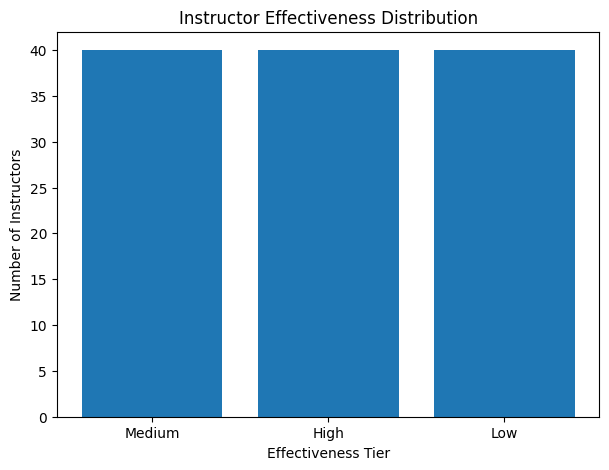

In [24]:
tier_counts = instructor_df[
    'effectiveness_tier'
].value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    tier_counts.index,
    tier_counts.values
)

plt.title('Instructor Effectiveness Distribution')

plt.xlabel('Effectiveness Tier')
plt.ylabel('Number of Instructors')

plt.show()

In [25]:
top_instructors = instructor_df.sort_values(
    'instructor_effectiveness_score',
    ascending=False
)

display(
    top_instructors[
        ['instructor_id',
         'total_batches',
         'total_courses',
         'instructor_effectiveness_score',
         'effectiveness_tier']
    ].head(10)
)

,instructor_id,total_batches,total_courses,instructor_effectiveness_score,effectiveness_tier
9,I_010,13,10,85.729921,High
36,I_037,15,12,84.072898,High
17,I_018,14,11,82.435024,High
104,I_105,16,12,81.748785,High
90,I_091,8,7,81.347477,High
4,I_005,19,13,79.986900,High
117,I_118,19,14,79.509956,High
24,I_025,19,14,78.718850,High
14,I_015,17,11,77.908839,High
50,I_051,26,15,77.583821,High


**Stage 5 - Machine Learning Model Development**
Objective: Predict instructor effectiveness tiers using classical ML algorithms.

We will use:
1. Logistic Regression
2. Random Forest Classifier

In [26]:
from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [27]:
features = [

    'completion_rate',

    'dropout_rate',

    'avg_score_improvement',

    'avg_quiz_score',

    'avg_watch_time',

    'assignment_submission_rate',

    'forum_activity_rate',

    'avg_feedback_score',

    'feedback_response_rate',

    'total_batches',

    'total_courses',

    'completion_rate_std',

    'dropout_rate_std',

    'avg_quiz_score_std',

    'avg_watch_time_std',

    'avg_feedback_score_std'

]

X = instructor_df[features]

y = instructor_df['effectiveness_tier']

print("Independent Variables:", X.shape)

print("Target Variable:", y.shape)

Independent Variables: (120, 16)
Target Variable: (120,)


In [28]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.25,

    random_state=42,

    stratify=y

)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (90, 16)
Testing Data: (30, 16)


In [29]:
logistic_model = Pipeline([

    ('imputer', SimpleImputer(strategy='median')),

    ('scaler', StandardScaler()),

    ('model', LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ))

])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression Trained!")

Logistic Regression Trained!


In [30]:
rf_model = Pipeline([

    ('imputer', SimpleImputer(strategy='median')),

    ('model', RandomForestClassifier(

        n_estimators=300,

        max_depth=None,

        min_samples_split=2,

        min_samples_leaf=2,

        class_weight='balanced',

        random_state=42

    ))

])

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Trained!")

Random Forest Trained!


In [31]:
dummy_model = Pipeline([

    ('imputer', SimpleImputer(strategy='median')),

    ('model', DummyClassifier(
        strategy='most_frequent'
    ))

])

dummy_model.fit(X_train, y_train)

dummy_predictions = dummy_model.predict(X_test)

**Stage 6 - Model Evaluation & Interpretation**
Objective: Compare the models and understand how accurately they predict instructor tiers.

In [32]:
models = {

    'Dummy Baseline': dummy_predictions,

    'Logistic Regression': logistic_predictions,

    'Random Forest': rf_predictions

}

results = []

for name, predictions in models.items():

    accuracy = accuracy_score(
        y_test,
        predictions
    )

    precision = precision_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        average='macro',
        zero_division=0
    )

    results.append({

        'Model': name,

        'Accuracy': accuracy,

        'Precision': precision,

        'Recall': recall,

        'F1 Score': f1

    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Dummy Baseline,0.333,0.111,0.333,0.167
1,Logistic Regression,0.900,0.899,0.900,0.898
2,Random Forest,1.000,1.000,1.000,1.000


<Figure size 900x500 with 0 Axes>

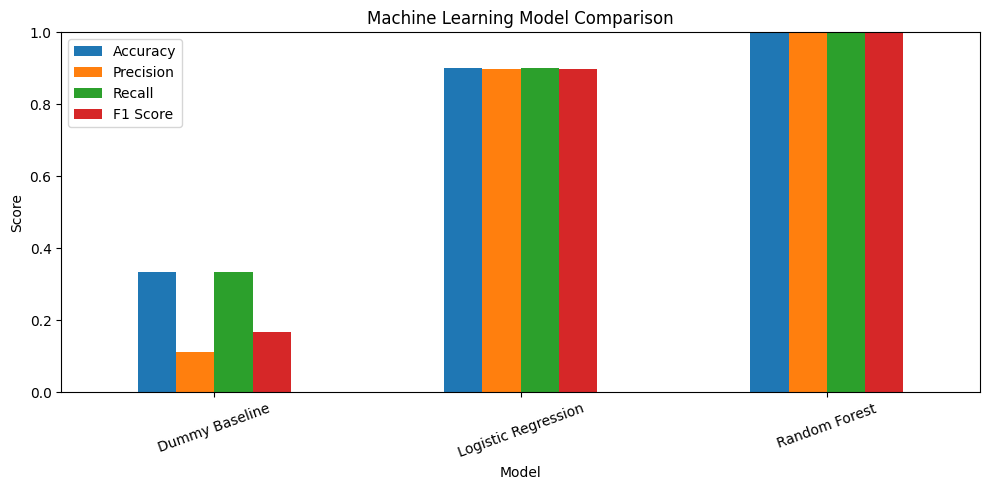

In [33]:
plt.figure(figsize=(9, 5))

results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(10, 5))

plt.title('Machine Learning Model Comparison')

plt.ylabel('Score')

plt.ylim(0, 1)

plt.xticks(rotation=20)

plt.tight_layout()

plt.show()

In [34]:
print("LOGISTIC REGRESSION REPORT")

print(
    classification_report(
        y_test,
        logistic_predictions,
        zero_division=0
    )
)

print("\nRANDOM FOREST REPORT")

print(
    classification_report(
        y_test,
        rf_predictions,
        zero_division=0
    )
)

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

        High       0.91      1.00      0.95        10
         Low       0.90      0.90      0.90        10
      Medium       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30


RANDOM FOREST REPORT
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        10
         Low       1.00      1.00      1.00        10
      Medium       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



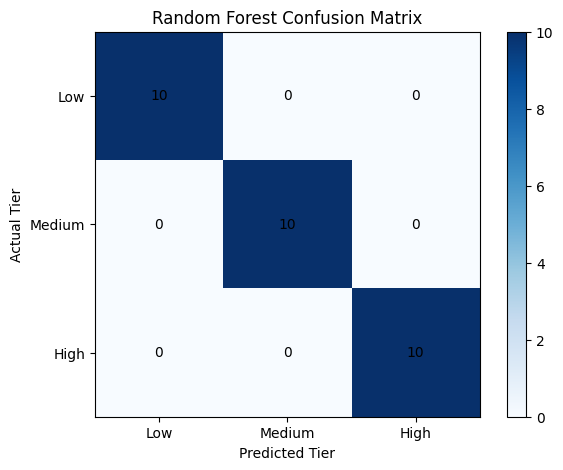

In [35]:
labels = ['Low', 'Medium', 'High']

cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=labels
)

plt.figure(figsize=(7, 5))

plt.imshow(cm, cmap='Blues')

plt.colorbar()

plt.xticks(
    range(3),
    labels
)

plt.yticks(
    range(3),
    labels
)

plt.xlabel('Predicted Tier')

plt.ylabel('Actual Tier')

plt.title('Random Forest Confusion Matrix')

for i in range(3):

    for j in range(3):

        plt.text(
            j,
            i,
            cm[i, j],
            ha='center',
            va='center'
        )

plt.show()

In [36]:
rf = rf_model.named_steps['model']

feature_importance = pd.DataFrame({

    'Feature': features,

    'Importance': rf.feature_importances_

})

feature_importance = feature_importance.sort_values(

    by='Importance',

    ascending=False

)

display(feature_importance)

,Feature,Importance
0,completion_rate,0.231547
1,dropout_rate,0.229526
2,avg_score_improvement,0.114273
8,feedback_response_rate,0.108497
3,avg_quiz_score,0.082170
7,avg_feedback_score,0.080234
4,avg_watch_time,0.038302
6,forum_activity_rate,0.033754
5,assignment_submission_rate,0.030130
13,avg_quiz_score_std,0.012757


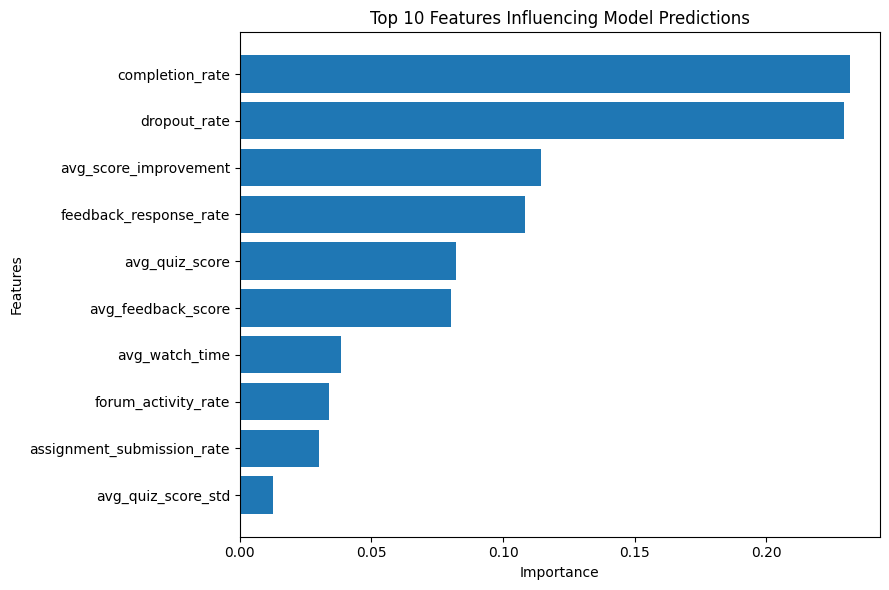

In [37]:
top_features = feature_importance.head(10)

plt.figure(figsize=(9, 6))

plt.barh(

    top_features['Feature'],

    top_features['Importance']

)

plt.xlabel('Importance')

plt.ylabel('Features')

plt.title('Top 10 Features Influencing Model Predictions')

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()

In [38]:
prediction_df = pd.DataFrame({

    'Actual_Tier': y_test.values,

    'Predicted_Tier': rf_predictions

})

display(prediction_df.head(20))

,Actual_Tier,Predicted_Tier
0,Medium,Medium
1,Low,Low
2,Low,Low
3,High,High
4,High,High
5,Low,Low
6,High,High
7,Medium,Medium
8,High,High
9,Low,Low


In [39]:
comparison = instructor_df.loc[
    X_test.index,
    ['instructor_id', 'instructor_effectiveness_score',
     'effectiveness_tier']
].copy()

comparison['Predicted_Tier'] = rf_predictions

comparison['Prediction_Status'] = np.where(

    comparison['effectiveness_tier'].astype(str) ==
    comparison['Predicted_Tier'],

    'Correct',

    'Incorrect'

)

display(comparison.head(20))

,instructor_id,instructor_effectiveness_score,effectiveness_tier,Predicted_Tier,Prediction_Status
41,I_042,66.744232,Medium,Medium,Correct
114,I_115,65.168459,Low,Low,Correct
60,I_061,57.899919,Low,Low,Correct
116,I_117,72.197729,High,High,Correct
13,I_014,74.105324,High,High,Correct
75,I_076,60.776731,Low,Low,Correct
29,I_030,75.689053,High,High,Correct
54,I_055,70.225800,Medium,Medium,Correct
17,I_018,82.435024,High,High,Correct
74,I_075,51.937560,Low,Low,Correct


**Mandatory Analysis Questions**

Q1. Which features most influenced instructor effectiveness, and why?

Answer:
The important features should be identified from the Random Forest feature importance chart. Completion rate, dropout rate, score improvement, quiz score, watch time and feedback are meaningful indicators because they measure learner outcomes, engagement and experience.

Q2. Which variables could be misleading or confounded?

Answer:
- Feedback score may be affected by learner expectations.
- Completion rate may depend on course difficulty.
- Quiz scores may depend on prior knowledge.
- Watch time does not always represent actual learning.
- Forum activity may vary by course requirements.
- Batch size and learner composition can influence outcomes.

Q3. How could this model fail in real-world usage?

Answer:

The model could fail when applied to new courses, different learner populations or new teaching formats. It may also produce misleading predictions due to biased feedback, insufficient instructor data and changes in course difficulty.

Q4. What additional data would you want to improve this analysis?

Answer:
- Number of learners in each batch.
- Learner attendance.
- Previous learner knowledge.
- Course difficulty and duration.
- Instructor experience.
- Assessment-level performance.
- Teaching hours.
- Learner support and satisfaction information.

Q5. Should this model be used for instructor performance evaluation? Why or why not?

Answer:

The model should not be used as the only method for instructor performance evaluation. It can support management decisions and identify areas for improvement, but it cannot independently measure teaching quality.

Human review, course context, learner feedback and transparent evaluation criteria are necessary before making important decisions